# ЛР02. Знакомство с инструментами сбора и подготовки данных

**Датасет:** CarPrice_Assignment.csv

1. Импорт датасета
2. Проверка пропусков и аномалий (статистика + визуализация), заполнение пропусков, устранение выбросов, повторная проверка
3. Генерация новых признаков (≥2) и кодирование категориальных (OHE, бинаризация)
4. Стандартизация и нормализация

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_PATH = Path("data/CarPrice_Assignment.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## 1. Импорт датасета

In [2]:
df = pd.read_csv(DATA_PATH)
print("Размер:", df.shape)
print("Столбцы:", list(df.columns))
df.head()

Размер: (205, 26)
Столбцы: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


## 2. Пропуски и аномальные значения

### 2.1. Исходные пропуски. Для демонстрации заполнения вносятся искусственные NaN (в исходном файле пропусков нет).

Пропуски в исходных данных:
 car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64
Всего пропусков: 0

Пропуски после внесения NaN:
 carbody        6
enginesize     8
horsepower    10
price          6
dtype: int64


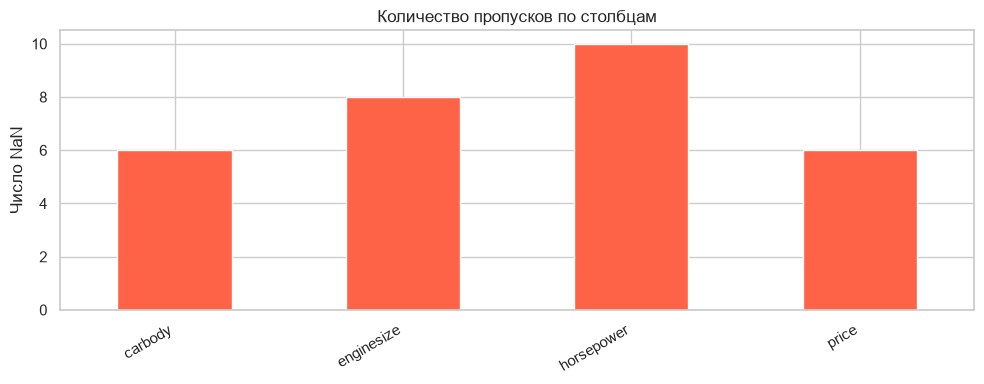

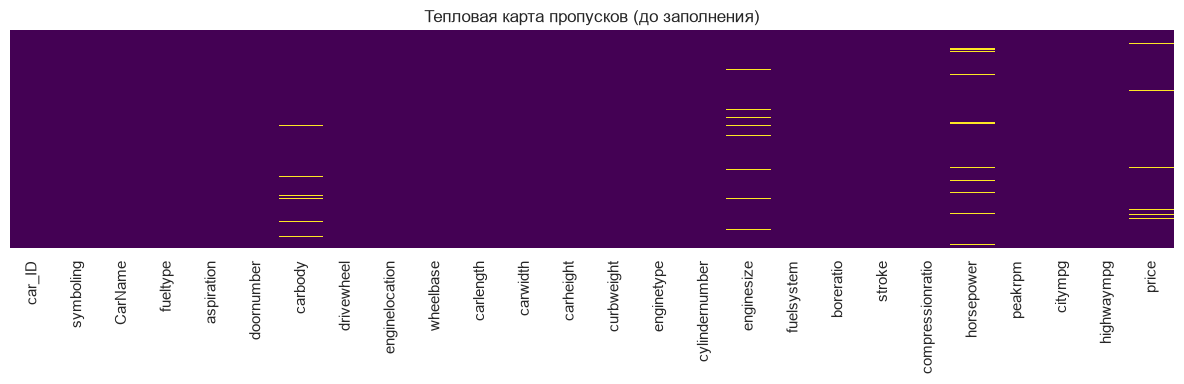

In [4]:
print("Пропуски в исходных данных:\n", df.isnull().sum())
print("Всего пропусков:", df.isnull().sum().sum())

rng = np.random.default_rng(42)
df_work = df.copy()
for col, frac in [("horsepower", 0.05), ("enginesize", 0.04), ("price", 0.03), ("carbody", 0.03)]:
    idx = rng.choice(df_work.index, size=max(1, int(len(df_work) * frac)), replace=False)
    df_work.loc[idx, col] = np.nan

missing = df_work.isnull().sum()
missing = missing[missing > 0]
print("\nПропуски после внесения NaN:\n", missing)

fig, ax = plt.subplots(figsize=(10, 4))
missing.plot(kind="bar", ax=ax, color="tomato")
ax.set_title("Количество пропусков по столбцам")
ax.set_ylabel("Число NaN")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_missing_before.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(df_work.isnull(), cbar=False, yticklabels=False, ax=ax, cmap="viridis")
ax.set_title("Тепловая карта пропусков (до заполнения)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_missing_heatmap_before.png", dpi=120)
plt.show()

### 2.2. Статистика и визуализация распределений / выбросов (до очистки)

                          mean          std      min      25%       50%  \
wheelbase            98.756585     6.021776    86.60    94.50     97.00   
carlength           174.049268    12.337289   141.10   166.30    173.20   
carwidth             65.907805     2.145204    60.30    64.10     65.50   
carheight            53.724878     2.443522    47.80    52.00     54.10   
curbweight         2555.565854   520.680204  1488.00  2145.00   2414.00   
enginesize          126.436548    40.288529    61.00    98.00    120.00   
boreratio             3.329756     0.270844     2.54     3.15      3.31   
stroke                3.255415     0.313597     2.07     3.11      3.29   
compressionratio     10.142537     3.972040     7.00     8.60      9.00   
horsepower          102.969231    37.427994    48.00    70.00     95.00   
peakrpm            5125.121951   476.985643  4150.00  4800.00   5200.00   
citympg              25.219512     6.542142    13.00    19.00     24.00   
highwaympg           30.7

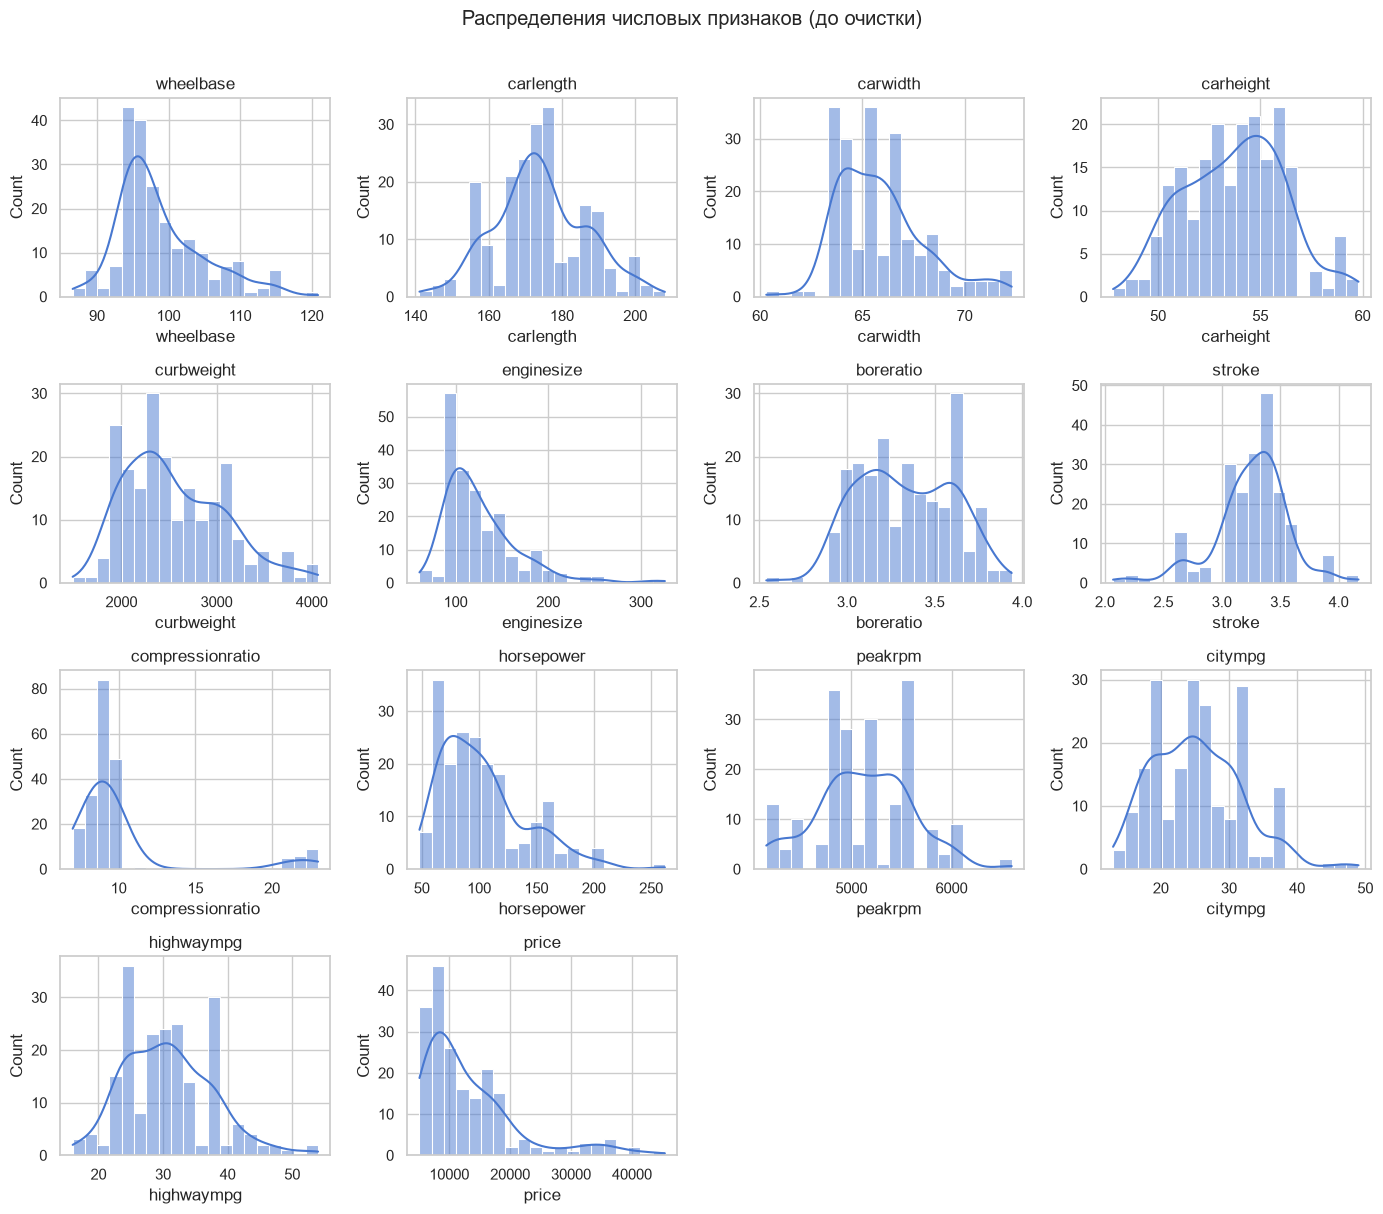

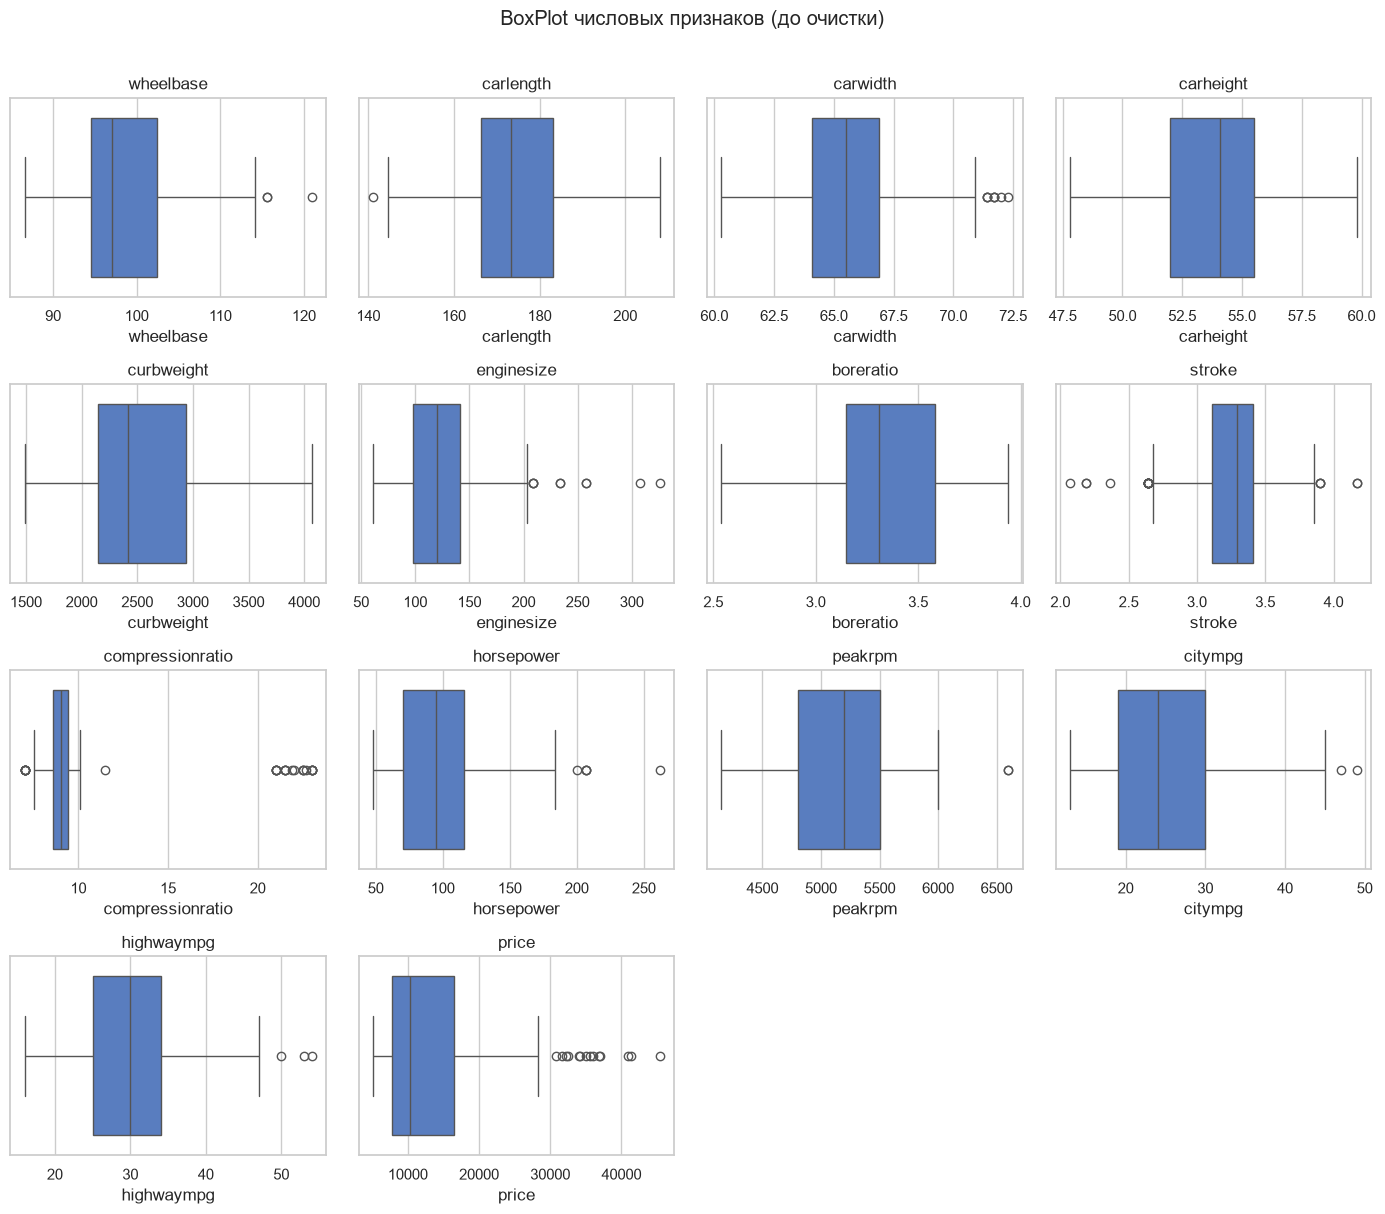

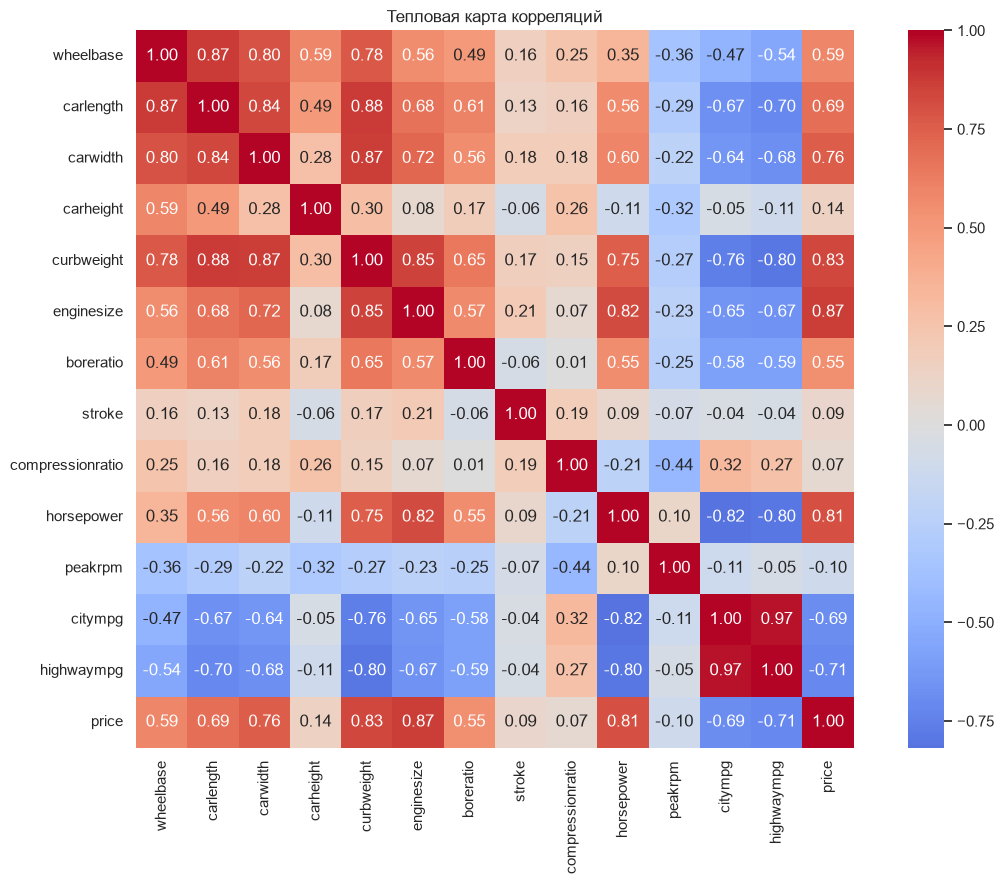

In [5]:
num_cols = [
    "wheelbase", "carlength", "carwidth", "carheight", "curbweight",
    "enginesize", "boreratio", "stroke", "compressionratio",
    "horsepower", "peakrpm", "citympg", "highwaympg", "price",
]

print(df_work[num_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]])

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    sns.histplot(df_work[col].dropna(), kde=True, ax=axes[i], bins=20)
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.suptitle("Распределения числовых признаков (до очистки)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_hist_before.png", dpi=120, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    sns.boxplot(x=df_work[col].dropna(), ax=axes[i])
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.suptitle("BoxPlot числовых признаков (до очистки)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_boxplot_before.png", dpi=120, bbox_inches="tight")
plt.show()

corr = df_work[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Тепловая карта корреляций")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_corr_heatmap.png", dpi=120)
plt.show()

### 2.3. Заполнение пропусков и устранение выбросов (IQR)

In [6]:
def fill_missing(data: pd.DataFrame) -> pd.DataFrame:
    out = data.copy()
    for col in out.columns:
        if out[col].isnull().any():
            if pd.api.types.is_numeric_dtype(out[col]):
                out[col] = out[col].fillna(out[col].median())
            else:
                out[col] = out[col].fillna(out[col].mode().iloc[0])
    return out


def remove_outliers_iqr(data: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    out = data.copy()
    mask = pd.Series(True, index=out.index)
    for col in columns:
        q1 = out[col].quantile(0.25)
        q3 = out[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        col_mask = (out[col] >= low) & (out[col] <= high)
        print(f"{col}: границы [{low:.2f}, {high:.2f}], выбросов: {(~col_mask).sum()}")
        mask &= col_mask
    return out.loc[mask].reset_index(drop=True)


df_filled = fill_missing(df_work)
print("Пропусков после заполнения:", df_filled.isnull().sum().sum())

outlier_cols = ["enginesize", "horsepower", "price", "compressionratio", "citympg", "highwaympg"]
print(f"\nСтрок до удаления выбросов: {len(df_filled)}")
df_clean = remove_outliers_iqr(df_filled, outlier_cols)
print(f"Строк после удаления выбросов: {len(df_clean)}")

Пропусков после заполнения: 0

Строк до удаления выбросов: 205
enginesize: границы [33.50, 205.50], выбросов: 9
horsepower: границы [1.00, 185.00], выбросов: 5
price: границы [-5280.00, 29568.00], выбросов: 14
compressionratio: границы [7.40, 10.60], выбросов: 28
citympg: границы [2.50, 46.50], выбросов: 2
highwaympg: границы [11.50, 47.50], выбросов: 3
Строк после удаления выбросов: 162


### 2.4. Проверка: пропуски и аномалии отсутствуют

Пропуски после очистки:
 car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64
Всего пропусков: 0


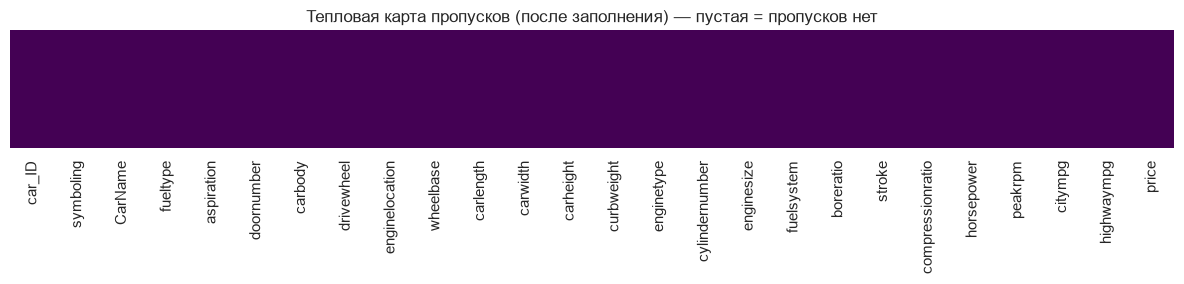

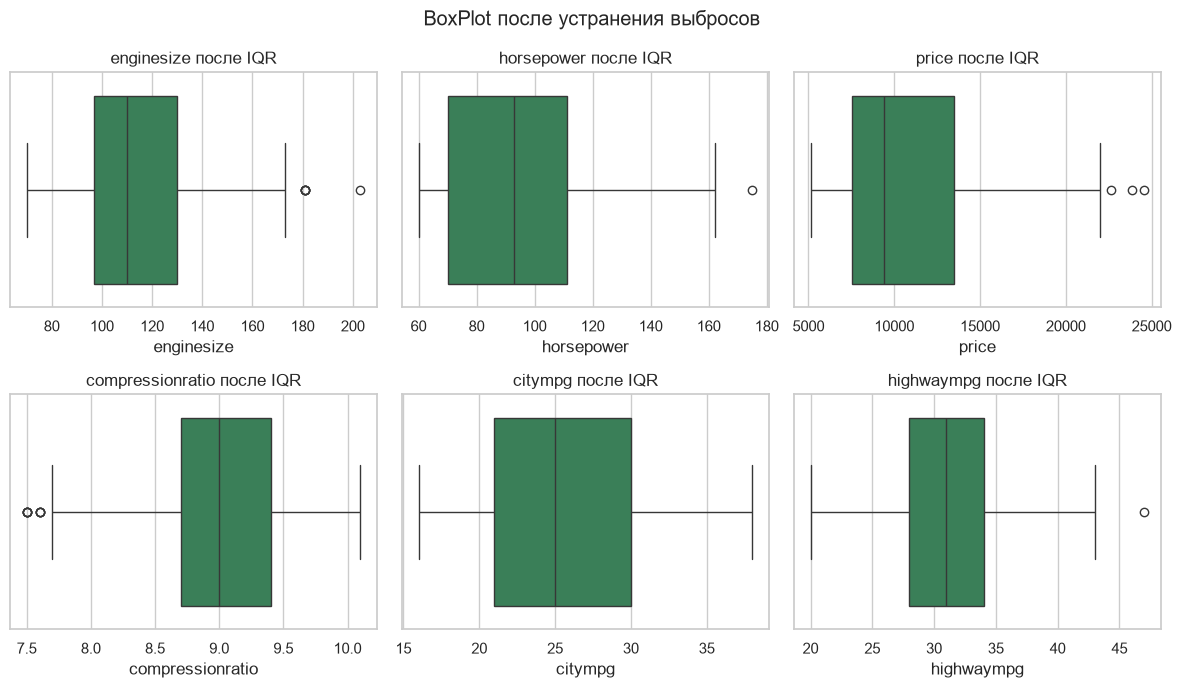

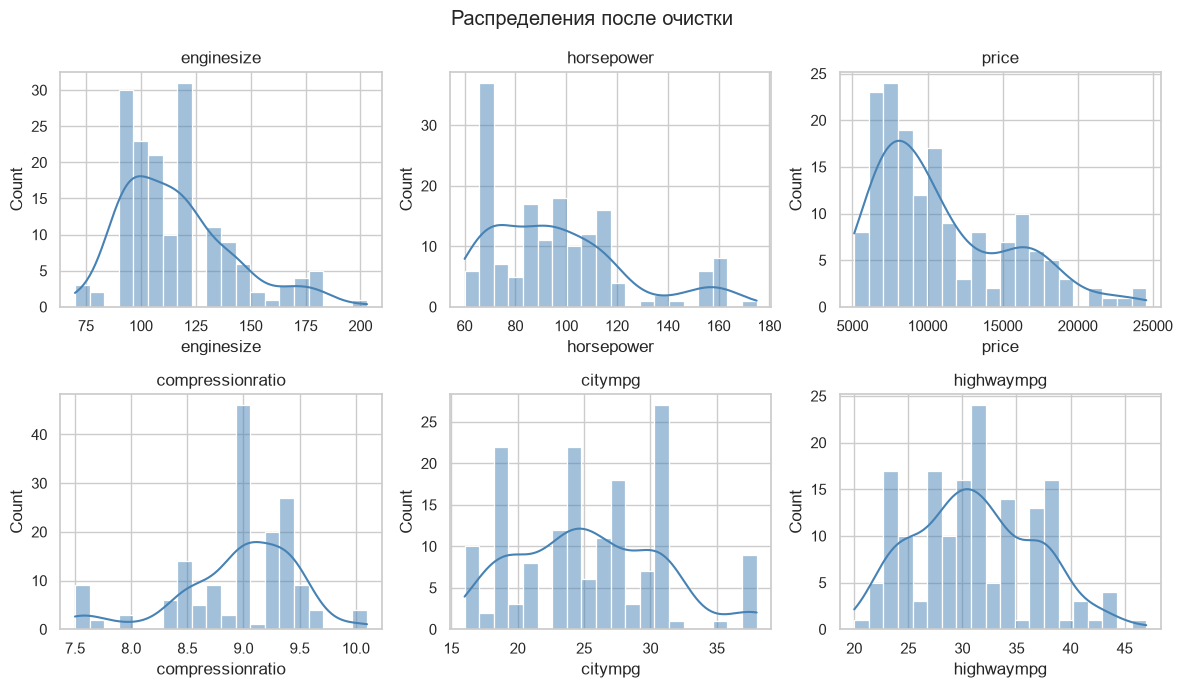

Проверка IQR после очистки:
  enginesize: оставшихся выбросов по IQR = 6
  horsepower: оставшихся выбросов по IQR = 1
  price: оставшихся выбросов по IQR = 3
  compressionratio: оставшихся выбросов по IQR = 9
  citympg: оставшихся выбросов по IQR = 0
  highwaympg: оставшихся выбросов по IQR = 1


In [7]:
print("Пропуски после очистки:\n", df_clean.isnull().sum())
print("Всего пропусков:", df_clean.isnull().sum().sum())

fig, ax = plt.subplots(figsize=(12, 3))
sns.heatmap(df_clean.isnull(), cbar=False, yticklabels=False, ax=ax, cmap="viridis")
ax.set_title("Тепловая карта пропусков (после заполнения) — пустая = пропусков нет")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_missing_heatmap_after.png", dpi=120)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()
for i, col in enumerate(outlier_cols):
    sns.boxplot(x=df_clean[col], ax=axes[i], color="seagreen")
    axes[i].set_title(f"{col} после IQR")
plt.suptitle("BoxPlot после устранения выбросов")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_boxplot_after.png", dpi=120)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()
for i, col in enumerate(outlier_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], bins=20, color="steelblue")
    axes[i].set_title(col)
plt.suptitle("Распределения после очистки")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_hist_after.png", dpi=120)
plt.show()

print("Проверка IQR после очистки:")
for col in outlier_cols:
    q1, q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f"  {col}: оставшихся выбросов по IQR = {n_out}")

## 3. Новые признаки и кодирование категориальных

Новые признаки:
         brand  power_to_weight  avg_mpg  car_volume
0  alfa-romero         0.043564     24.0  528019.904
1  alfa-romero         0.043564     24.0  528019.904
2  alfa-romero         0.054552     22.5  587592.640
3         audi         0.043646     27.0  634816.956
4         audi         0.040722     20.0  636734.832
5         audi         0.043877     22.0  624189.969
6         audi         0.038678     22.0  766364.046
7         audi         0.037238     22.0  766364.046
8         audi         0.045366     18.5  769115.802
9          bmw         0.042171     26.0  622095.552


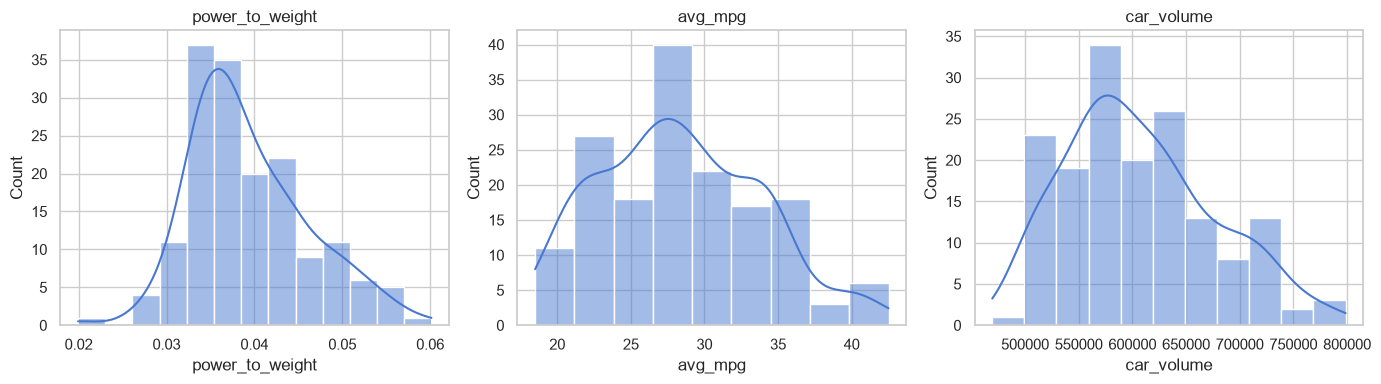

In [8]:
df_feat = df_clean.copy()

df_feat["brand"] = df_feat["CarName"].str.split().str[0].str.lower()
df_feat["brand"] = df_feat["brand"].replace({
    "maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
    "vokswagen": "volkswagen", "vw": "volkswagen",
})

df_feat["power_to_weight"] = df_feat["horsepower"] / df_feat["curbweight"]
df_feat["avg_mpg"] = (df_feat["citympg"] + df_feat["highwaympg"]) / 2
df_feat["car_volume"] = df_feat["carlength"] * df_feat["carwidth"] * df_feat["carheight"]

print("Новые признаки:")
print(df_feat[["brand", "power_to_weight", "avg_mpg", "car_volume"]].head(10))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df_feat["power_to_weight"], kde=True, ax=axes[0])
axes[0].set_title("power_to_weight")
sns.histplot(df_feat["avg_mpg"], kde=True, ax=axes[1])
axes[1].set_title("avg_mpg")
sns.histplot(df_feat["car_volume"], kde=True, ax=axes[2])
axes[2].set_title("car_volume")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_new_features.png", dpi=120)
plt.show()

In [9]:
df_enc = df_feat.copy()

df_enc["fueltype_bin"] = (df_enc["fueltype"] == "diesel").astype(int)
df_enc["aspiration_bin"] = (df_enc["aspiration"] == "turbo").astype(int)
df_enc["doornumber_bin"] = (df_enc["doornumber"] == "four").astype(int)
df_enc["enginelocation_bin"] = (df_enc["enginelocation"] == "rear").astype(int)

print("Бинаризация:")
print(df_enc[["fueltype", "fueltype_bin", "aspiration", "aspiration_bin",
              "doornumber", "doornumber_bin"]].head())

le = LabelEncoder()
df_enc["drivewheel_le"] = le.fit_transform(df_enc["drivewheel"])
print("\nLabelEncoder drivewheel:", dict(zip(le.classes_, le.transform(le.classes_))))

ohe_cols = ["carbody", "enginetype", "fuelsystem"]
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe_arr = ohe.fit_transform(df_enc[ohe_cols])
ohe_names = ohe.get_feature_names_out(ohe_cols)
df_ohe = pd.DataFrame(ohe_arr, columns=ohe_names, index=df_enc.index)

df_enc = pd.concat([df_enc, df_ohe], axis=1)
print("\nOHE-признаки (фрагмент):")
print(df_ohe.iloc[:5, :8])
print("Всего OHE-столбцов:", len(ohe_names))

Бинаризация:
  fueltype  fueltype_bin aspiration  aspiration_bin doornumber  doornumber_bin
0      gas             0        std               0        two               0
1      gas             0        std               0        two               0
2      gas             0        std               0        two               0
3      gas             0        std               0       four               1
4      gas             0        std               0       four               1

LabelEncoder drivewheel: {'4wd': np.int64(0), 'fwd': np.int64(1), 'rwd': np.int64(2)}

OHE-признаки (фрагмент):
   carbody_convertible  carbody_hardtop  carbody_hatchback  carbody_sedan  \
0                  1.0              0.0                0.0            0.0   
1                  1.0              0.0                0.0            0.0   
2                  0.0              0.0                1.0            0.0   
3                  0.0              0.0                0.0            1.0   
4              

## 4. Стандартизация и нормализация

До масштабирования:
             price  horsepower   curbweight
mean  10897.469136   96.512346  2429.222222
std    4428.302577   27.117237   402.554560
min    5118.000000   60.000000  1819.000000
max   24565.000000  175.000000  3366.000000

После StandardScaler (mean≈0, std≈1):
         price_std  horsepower_std  curbweight_std
mean  1.644775e-16    1.754427e-16    1.535123e-16
std   1.003101e+00    1.003101e+00    1.003101e+00
min  -1.309168e+00   -1.350638e+00   -1.520575e+00
max   3.095974e+00    2.903357e+00    2.334299e+00

После MinMaxScaler ([0, 1]):
      price_mm  horsepower_mm  curbweight_mm
mean  0.297191       0.317499       0.394455
std   0.227711       0.235802       0.260216
min   0.000000       0.000000       0.000000
max   1.000000       1.000000       1.000000


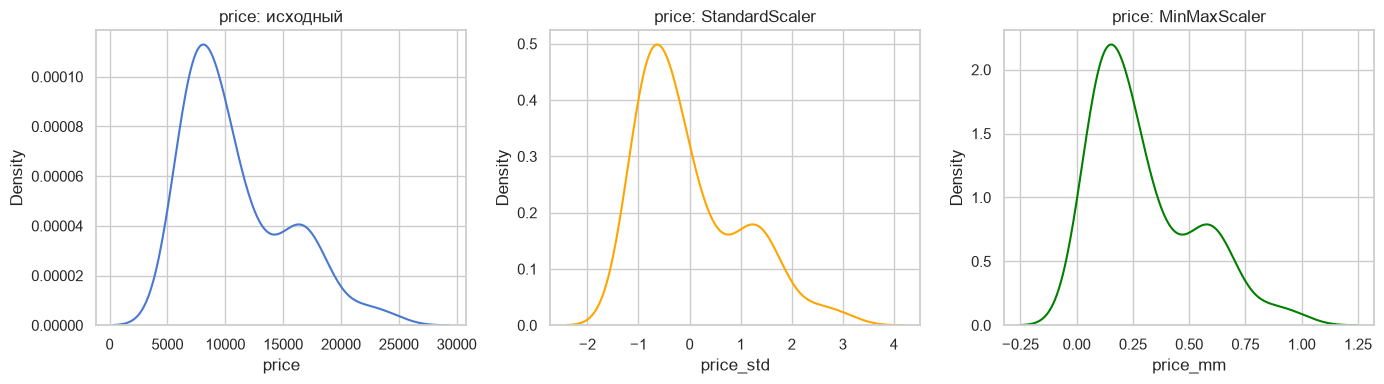


Итоговый датасет сохранён: D:\MMO\lab2\data\CarPrice_prepared.csv
Размер: (162, 87)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,stroke_mm,compressionratio_mm,horsepower_mm,peakrpm_mm,citympg_mm,highwaympg_mm,price_mm,power_to_weight_mm,avg_mpg_mm,car_volume_mm
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,0.333333,0.576923,0.443478,0.333333,0.227273,0.259259,0.430761,0.587733,0.229167,0.178096
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,0.333333,0.576923,0.443478,0.333333,0.227273,0.259259,0.585283,0.587733,0.229167,0.178096
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,0.765027,0.576923,0.817391,0.333333,0.136364,0.222222,0.585283,0.861062,0.166667,0.359052
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,0.726776,0.961538,0.365217,0.541667,0.363636,0.370370,0.454157,0.589775,0.354167,0.502499
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,0.726776,0.192308,0.478261,0.541667,0.090909,0.074074,0.634134,0.517059,0.062500,0.508325


In [10]:
scale_cols = [
    "wheelbase", "carlength", "carwidth", "carheight", "curbweight",
    "enginesize", "boreratio", "stroke", "compressionratio",
    "horsepower", "peakrpm", "citympg", "highwaympg", "price",
    "power_to_weight", "avg_mpg", "car_volume",
]

X = df_enc[scale_cols].copy()

scaler_std = StandardScaler()
X_std = pd.DataFrame(scaler_std.fit_transform(X), columns=[f"{c}_std" for c in scale_cols])

scaler_mm = MinMaxScaler()
X_mm = pd.DataFrame(scaler_mm.fit_transform(X), columns=[f"{c}_mm" for c in scale_cols])

print("До масштабирования:")
print(X[["price", "horsepower", "curbweight"]].describe().loc[["mean", "std", "min", "max"]])
print("\nПосле StandardScaler (mean≈0, std≈1):")
print(X_std[["price_std", "horsepower_std", "curbweight_std"]].describe().loc[["mean", "std", "min", "max"]])
print("\nПосле MinMaxScaler ([0, 1]):")
print(X_mm[["price_mm", "horsepower_mm", "curbweight_mm"]].describe().loc[["mean", "std", "min", "max"]])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.kdeplot(X["price"], ax=axes[0], label="исходный")
axes[0].set_title("price: исходный")
sns.kdeplot(X_std["price_std"], ax=axes[1], color="orange")
axes[1].set_title("price: StandardScaler")
sns.kdeplot(X_mm["price_mm"], ax=axes[2], color="green")
axes[2].set_title("price: MinMaxScaler")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_scaling.png", dpi=120)
plt.show()

df_final = pd.concat(
    [
        df_enc.reset_index(drop=True),
        X_std.reset_index(drop=True),
        X_mm.reset_index(drop=True),
    ],
    axis=1,
)
out_path = Path("data/CarPrice_prepared.csv")
df_final.to_csv(out_path, index=False)
print(f"\nИтоговый датасет сохранён: {out_path.resolve()}")
print("Размер:", df_final.shape)
df_final.head()